In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [20]:
motor_cal = pd.read_csv('/Users/meghnaanand/Desktop/Analysis/motorcalibrationvalues.csv')
m = motor_cal.loc[motor_cal['parameter'] == 'slope_m', 'value'].values[0]
b = motor_cal.loc[motor_cal['parameter'] == 'intercept_b', 'value'].values[0]
print(f'Motor calibration: m={m:.4f} cm/V, b={b:.4f} cm')

Motor calibration: m=-0.1176 cm/V, b=-0.0027 cm


In [21]:
attachment_distances = pd.DataFrame({
    'moth': ['m20_wn2', 'm23_wn2', 'm29_wn2', 'm30_wn1', 'm31_wn2'],
    'attachment_distance_cm': [1.2, 0.7, 0.7, 0.8, 0.7]})
attachment_distances.to_csv('/Users/meghnaanand/Desktop/Analysis/moth_attachment_distances.csv', index=False)
attachment_distances = pd.read_csv('/Users/meghnaanand/Desktop/Analysis/moth_attachment_distances.csv')
print(attachment_distances)

      moth  attachment_distance_cm
0  m20_wn2                     1.2
1  m23_wn2                     0.7
2  m29_wn2                     0.7
3  m30_wn1                     0.8
4  m31_wn2                     0.7


In [22]:
moth = 'm23_wn2'  # change this each time
attachment_distance_cm = attachment_distances.loc[
    attachment_distances['moth'] == moth, 'attachment_distance_cm'
].values[0]
print(f'Moth: {moth}, attachment distance: {attachment_distance_cm} cm')

Moth: m23_wn2, attachment distance: 0.7 cm


In [23]:
scaled_voltage = pd.read_csv(
    f'/Users/meghnaanand/Desktop/Analysis/{moth}_scaledvoltage.csv'
)['scaled_voltage']

displacement_cm = m * scaled_voltage + b
angle_degrees = np.degrees(np.arctan(displacement_cm / attachment_distance_cm))

result_df = pd.DataFrame({
    'scaled_voltage': scaled_voltage,
    'displacement_cm': displacement_cm,
    'angle_degrees': angle_degrees
})
result_df.to_csv(f'/Users/meghnaanand/Desktop/Analysis/{moth}_degrees.csv', index=False)
print(f'{moth}: angle range {angle_degrees.min():.2f}° to {angle_degrees.max():.2f}°')

m23_wn2: angle range -22.81° to 34.40°


In [14]:
scaled_voltage = pd.read_csv(
    f'/Users/meghnaanand/Desktop/Analysis/{moth}_scaledvoltage.csv'
)['scaled_voltage']

print(f'Loaded {len(scaled_voltage)} rows')
print(f'Voltage range: {scaled_voltage.min():.4f} to {scaled_voltage.max():.4f} V')

Loaded 10849920 rows
Voltage range: -3.1097 to 1.8767 V


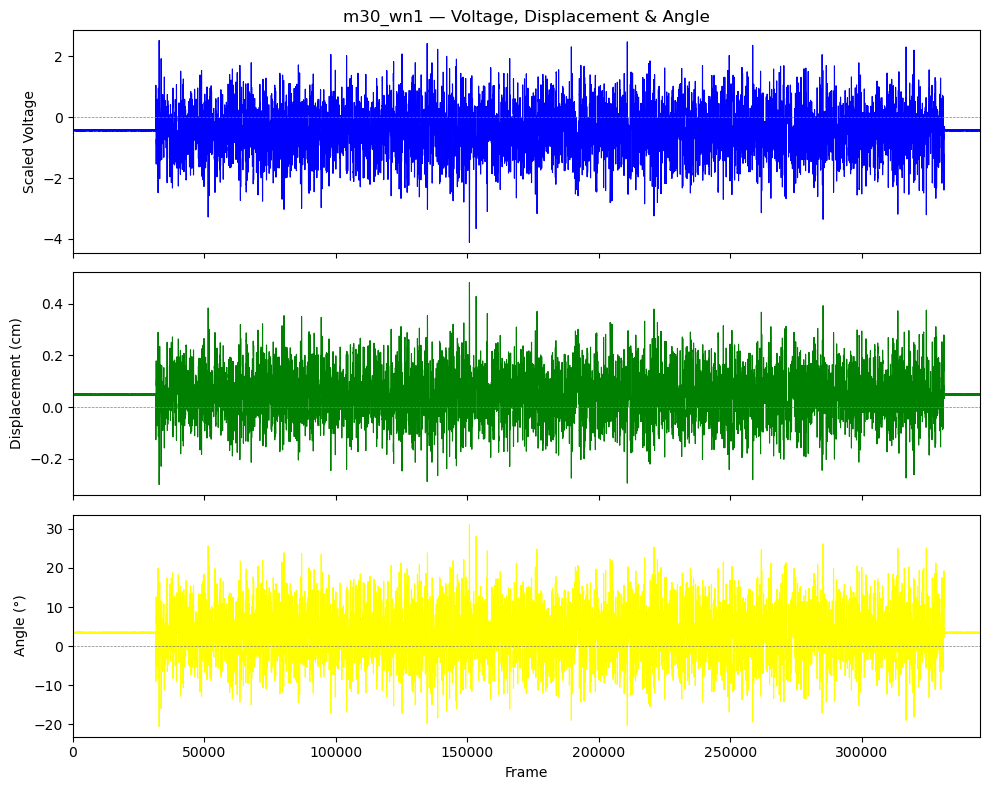

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

Fs = 3e4

axes[0].plot(result_df['scaled_voltage'], color='blue', linewidth=0.8)
axes[0].set_ylabel('Scaled Voltage')
axes[0].set_title(f'{moth} — Voltage, Displacement & Angle')

axes[1].plot(result_df['displacement_cm'], color='green', linewidth=0.8)
axes[1].set_ylabel('Displacement (cm)')

axes[2].plot(result_df['angle_degrees'], color='yellow', linewidth=0.8)
axes[2].set_ylabel('Angle (°)')
axes[2].set_xlabel('Frame')

for ax in axes:
    ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    ax.set_xlim(0, int(11.5 * Fs))  

plt.tight_layout()
filename = f"/Users/meghnaanand/Desktop/Analysis/{moth}_anglewaveforms.pdf"
plt.savefig(filename)
plt.show()

